# 📈 05 - Titanic Model Evaluation & Diagnostics

This notebook conducts in-depth model evaluation, diagnostic curve plotting, and error analysis on the trained Titanic survival model.

### Contents:
1. Performance Metrics (Accuracy, Precision, Recall, F1, ROC-AUC).
2. Confusion Matrix Heatmap.
3. Receiver Operating Characteristic (ROC) and Precision-Recall Curves.
4. Global Feature Importance Analysis.
5. Sample Prediction Demonstrations.


In [1]:
import sys
from pathlib import Path
import joblib
import json
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.metrics import classification_report, roc_curve, precision_recall_curve

sys.path.append(str(Path("..").resolve()))
from src.data_loader import load_raw_data
from src.predict import TitanicPredictor
from src.evaluate import calculate_metrics, plot_confusion_matrix, plot_roc_curve, plot_feature_importance

# Load model and raw data
predictor = TitanicPredictor("../models/titanic_model.joblib")
raw_df = load_raw_data("../data/raw/train.csv")
X = raw_df.drop(columns=["Survived"])
y = raw_df["Survived"]

y_pred = predictor.predict(X)
y_prob = predictor.predict_proba(X)
metrics = calculate_metrics(y.to_numpy(), np.array(y_pred), np.array(y_prob))
print("Model Evaluation Summary:")
print(f"Accuracy:  {metrics['accuracy']*100:.2f}%")
print(f"Precision: {metrics['precision']*100:.2f}%")
print(f"Recall:    {metrics['recall']*100:.2f}%")
print(f"F1-Score:  {metrics['f1']:.4f}")
print(f"ROC-AUC:   {metrics['roc_auc']:.4f}")


Model Evaluation Summary:
Accuracy:  85.97%
Precision: 86.05%
Recall:    75.73%
F1-Score:  0.8056
ROC-AUC:   0.9274


## 1. Classification Report

In [2]:
print(classification_report(y, y_pred, target_names=["Did Not Survive (0)", "Survived (1)"]))


                     precision    recall  f1-score   support

Did Not Survive (0)       0.86      0.92      0.89       549
       Survived (1)       0.86      0.76      0.81       342

           accuracy                           0.86       891
          macro avg       0.86      0.84      0.85       891
       weighted avg       0.86      0.86      0.86       891



## 2. Confusion Matrix & ROC Curve

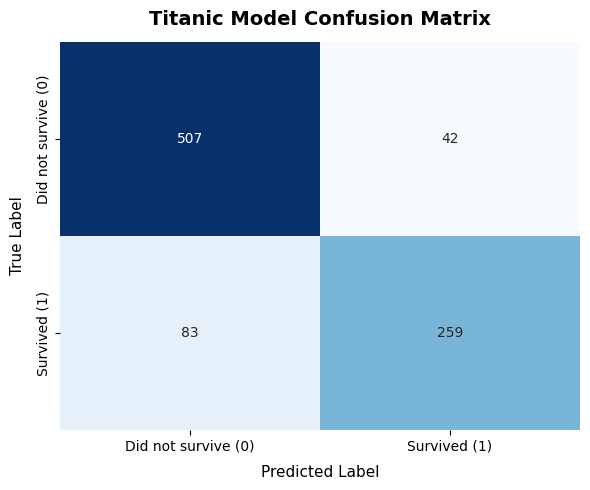

In [3]:
fig_cm = plot_confusion_matrix(y.to_numpy(), np.array(y_pred), title="Titanic Model Confusion Matrix")
plt.show()


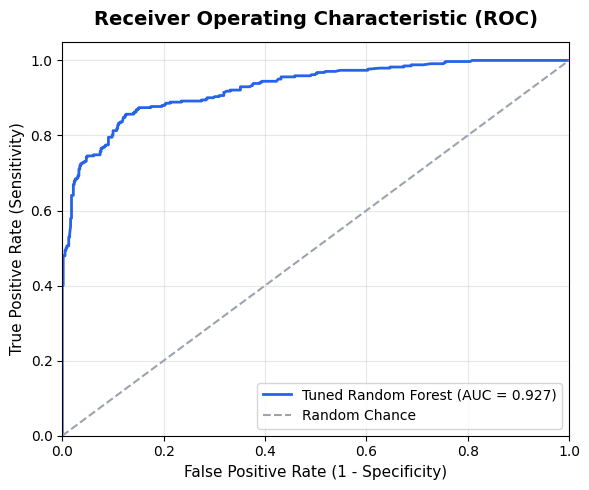

In [4]:
fig_roc = plot_roc_curve(y.to_numpy(), np.array(y_prob), model_name="Tuned Random Forest")
plt.show()


## 3. Global Feature Importance

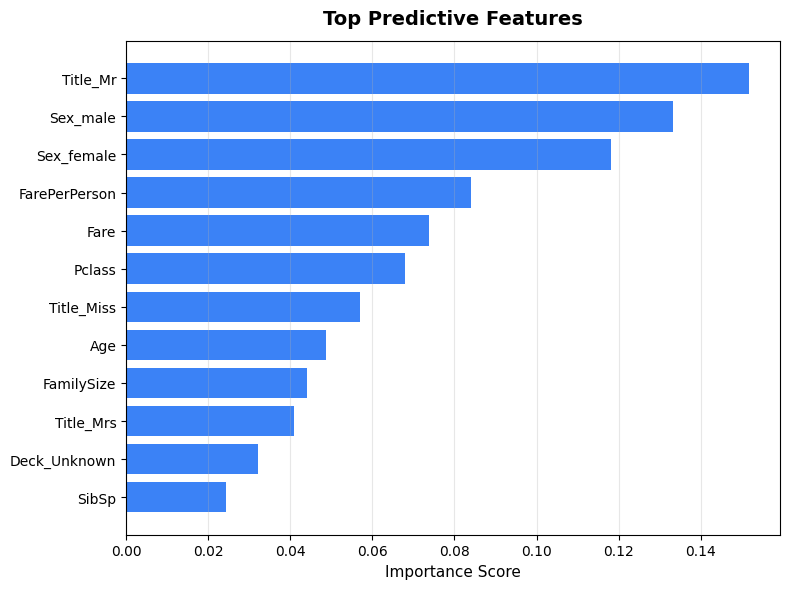

In [5]:
metrics_file = Path("../models/model_metrics.json")
if metrics_file.exists():
    with open(metrics_file, "r", encoding="utf-8") as f:
        meta = json.load(f)
    feat_names = meta.get("feature_names", [])
    importances = np.array(meta.get("feature_importances", []))
    if len(feat_names) > 0 and len(importances) > 0:
        fig_imp = plot_feature_importance(feat_names, importances, top_n=12, title="Top Predictive Features")
        plt.show()


## 4. End-to-End Individual Passenger Prediction

In [6]:
sample_passengers = [
    {
        "Pclass": 1,
        "Name": "Allison, Miss. Helen Loraine",
        "Sex": "female",
        "Age": 2.0,
        "SibSp": 1,
        "Parch": 2,
        "Fare": 151.55,
        "Cabin": "C22",
        "Embarked": "S"
    },
    {
        "Pclass": 3,
        "Name": "Svensson, Mr. Johan",
        "Sex": "male",
        "Age": 74.0,
        "SibSp": 0,
        "Parch": 0,
        "Fare": 7.775,
        "Cabin": "Unknown",
        "Embarked": "S"
    }
]

for p in sample_passengers:
    res = predictor.predict_detailed(p)
    print(f"Passenger: {p['Name']}")
    print(f" -> Predicted Outcome: {res['status']} ({res['confidence_percentage']})")
    print(f" -> Factors: {res['risk_and_protective_factors']}\n")


Passenger: Allison, Miss. Helen Loraine
 -> Predicted Outcome: Survived (74.0%)
 -> Factors: ['Female passenger (Historically highest survival rate ~74%)', 'First Class passenger (Priority lifeboat access)', "Child passenger ('Women and children first' protocol)"]

Passenger: Svensson, Mr. Johan
 -> Predicted Outcome: Did not survive (8.4%)
 -> Factors: ['Male passenger (Lower historical survival rate ~19%)', 'Third Class passenger (Lower deck location, lower survival chance)', 'Traveling alone']

